In [1]:
import sys
sys.path.append('../../../../')

import matplotlib.pyplot as plt
from labellines import labelLine, labelLines

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *
from Eigenvalues import *
import config

In [2]:
cs  = np.linspace(0, np.sqrt(2), 20, endpoint=False)
ks = np.linspace(-3, -6, 20) # k0 = -3.636

N = 800_001
L = 200

x = np.linspace(-L, L, N)

In [7]:
eigs = np.array([])
n = 0
c = cs[n]
for j in range(len(ks)):
    k = ks[j]

    h = x[1] - x[0]
    
    # import soliton file
    DS_path = f'DS_DB/DS_c_{c:.4f}_k_{k:.4f}.npy.gz'
    DS_file = gzip.GzipFile(DS_path, "r")
    us = np.load(DS_file)

    D1 = D1_neumann_centered(N, h)
    D2 = D2_neumann_centered(N, h)

    M, A, B = build_linearized_matrix(us, D1, D2, k, c)#, profs=(eta, theta))

    sigma = 0.01
    if k < -3.6316: #-6.1:
        sigma = 0.5
    evals, evecs = spla.eigs(M, k=1, which='LM', sigma=sigma)
    eigs = np.concatenate((eigs, evals))
    print(f'c = {c:.4f}, k = {k:.4f}, evals = {evals}, iteration = {n*len(ks)+j+1}/{len(cs[:6])*len(ks)}')

#save_file(eigs, f'Eigs_DS/eigs_c_{c:.4f}')

c = 0.0000, k = -3.0000, evals = [8.59038533e-06+0.j], iteration = 1/120
c = 0.0000, k = -3.1579, evals = [3.83459657e-06+0.j], iteration = 2/120
c = 0.0000, k = -3.3158, evals = [4.16023411e-06+0.j], iteration = 3/120
c = 0.0000, k = -3.4737, evals = [3.97109867e-06+0.j], iteration = 4/120
c = 0.0000, k = -3.6316, evals = [0.00276872+0.00339407j], iteration = 5/120
c = 0.0000, k = -3.7895, evals = [0.02394773+0.j], iteration = 6/120
c = 0.0000, k = -3.9474, evals = [0.04867577+0.j], iteration = 7/120
c = 0.0000, k = -4.1053, evals = [0.07339349+0.j], iteration = 8/120
c = 0.0000, k = -4.2632, evals = [0.09808711+0.j], iteration = 9/120
c = 0.0000, k = -4.4211, evals = [0.12276021+0.j], iteration = 10/120
c = 0.0000, k = -4.5789, evals = [0.14741244+0.j], iteration = 11/120
c = 0.0000, k = -4.7368, evals = [0.17204303+0.j], iteration = 12/120
c = 0.0000, k = -4.8947, evals = [0.19665141+0.j], iteration = 13/120
c = 0.0000, k = -5.0526, evals = [0.22123728+0.j], iteration = 14/120
c = 0

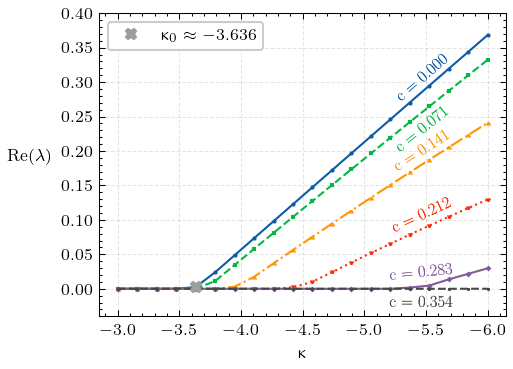

In [6]:
lines = []
for n in range(6):
    c = cs[n]
    eigs_file = gzip.GzipFile(f"Eigs_DS/eigs_c_{c:.4f}.npy.gz", "r")
    eigs_c = np.load(eigs_file)
    lines.extend(plt.plot(ks, eigs_c.real, ms=1, label=f'c = {c:.3f}'))

xvals = [-5.5, -5.5, -5.5, -5.5, -5.5, -5.5]
y_offset = [0.02, -0.025, 0.02, 0.02, 0.02, -0.02]

labelLines(lines, xvals=xvals, fontsize=8, backgroundcolor="none",
           drop_label=True, zorder=2.5, yoffsets=y_offset, outline_width=0)

plt.plot(-3.636, 0.00252439, ms=5, ls="", label=r'$\upkappa_0 \approx -3.636$')
plt.xlabel(r"$\upkappa$")
plt.ylabel(r"$\mathrm{Re}(\lambda)$", rotation='horizontal', ha='right')
ax=plt.gca()
ax.invert_xaxis()
plt.legend()
plt.ylim(-0.04, 0.4)

plt.savefig('Eigs_DS_k_c.pdf', bbox_inches='tight', dpi=300)
plt.show()